<a href="https://colab.research.google.com/github/Badhon63/Machine-Learning_Lab/blob/main/A2/05_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Machine Learning Lab**

# 7. Regression

**Regression** is a supervised-learning technique used to predict a continuous outcome from one or more predictor variables — for example, predicting a car's fuel efficiency from its weight and horsepower. The most common form is linear regression, valued for its simplicity and interpretability, but there are many other kinds (polynomial, tree-based, etc.), each suited to different data. A regression model's performance is typically judged by metrics like mean squared error (MSE), which measure how far predictions land from the true values.

## 7.1 Importing Modules

In [9]:
import pandas as pd
import numpy as np

## 7.2 Importing and Preprocessing the Dataset

The [Productivity Prediction of Garment Employees dataset](https://archive.ics.uci.edu/dataset/597/productivity+prediction+of+garment+employees) will be used for this task. It includes key attributes of the garment manufacturing process and the resulting productivity of employees, collected manually and validated by industry experts.

Attribute information:
```
01  date                  : Date in MM-DD-YYYY
02  day                   : Day of the Week
03  quarter               : A portion of the month. A month was divided into four quarters
04  department            : Associated department with the instance
05  team                  : Associated team number with the instance
06  no_of_workers         : Number of workers in each team
07  no_of_style_change    : Number of changes in the style of a particular product
08  targeted_productivity : Targeted productivity set by the Authority for each team for each day.
09  smv                   : Standard Minute Value, it is the allocated time for a task
10  wip                   : Work in progress. Includes the number of unfinished items for products
11  over_time             : Represents the amount of overtime by each team in minutes
12  incentive             : Represents the amount of financial incentive (in BDT) that enables or motivates a particular course of action.
13  idle_time             : The amount of time when the production was interrupted due to several reasons
14  idle_men              : The number of workers who were idle due to production interruption
15  actual_productivity   : The actual % of productivity that was delivered by the workers. It ranges from 0-1.
```

Run the cell below and upload `garments_worker_productivity.csv` (found in this notebook's folder in the repo) when prompted.

In [10]:
from google.colab import files
uploaded = files.upload()  # select garments_worker_productivity.csv

Saving data.csv to data (1).csv


In [12]:
# Optional: Only needed if you want to load data from your Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

Load the data and take a look at it.

In [13]:
# Importing the data
df = pd.read_csv('/content/data.csv')
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


Drop fully-empty


In [14]:
if 'df' not in locals() and 'df' not in globals():
    import pandas as pd
    df = pd.read_csv('/content/data.csv')

df = df.drop(columns=['Unnamed: 32'], errors='ignore')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Separate target and id

In [15]:
y = df['diagnosis']
X = df.drop(columns=['id', 'diagnosis'])
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Equation (1): Mean Imputation


In [16]:
X = X.fillna(X.mean())
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Encoding categorical variable

In [17]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


 Equation (2): Min-Max Scaling


In [18]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [19]:
print(X_scaled.head())
print("Encoded classes:", dict(zip(le.classes_, le.transform(le.classes_))))

   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0     0.521037      0.022658        0.545989   0.363733         0.593753   
1     0.643144      0.272574        0.615783   0.501591         0.289880   
2     0.601496      0.390260        0.595743   0.449417         0.514309   
3     0.210090      0.360839        0.233501   0.102906         0.811321   
4     0.629893      0.156578        0.630986   0.489290         0.430351   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0          0.792037        0.703140             0.731113       0.686364   
1          0.181768        0.203608             0.348757       0.379798   
2          0.431017        0.462512             0.635686       0.509596   
3          0.811361        0.565604             0.522863       0.776263   
4          0.347893        0.463918             0.518390       0.378283   

   fractal_dimension_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0           

Step 4: Perform the Train-Test Split First

In [22]:


from sklearn.model_selection import train_test_split

# 80:20 split, stratified by diagnosis, with a fixed random state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Verify the split
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape: ", y_test.shape)

# Check that class proportions are preserved in both subsets
print("\nClass proportion in full data:\n", y.value_counts(normalize=True).round(3))
print("\nClass proportion in training set:\n", y_train.value_counts(normalize=True).round(3))
print("\nClass proportion in test set:\n", y_test.value_counts(normalize=True).round(3))

X_train shape: (455, 30)
X_test shape:  (114, 30)
y_train shape: (455,)
y_test shape:  (114,)

Class proportion in full data:
 diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64

Class proportion in training set:
 diagnosis
B    0.626
M    0.374
Name: proportion, dtype: float64

Class proportion in test set:
 diagnosis
B    0.632
M    0.368
Name: proportion, dtype: float64


 Step 5: Handle Missing Values

In [23]:


import pandas as pd
from sklearn.impute import SimpleImputer

# Check the training data for missing values
print("Missing values in training data:\n", X_train.isnull().sum()[X_train.isnull().sum() > 0])
print("\nTotal missing values in X_train:", X_train.isnull().sum().sum())
print("Total missing values in X_test: ", X_test.isnull().sum().sum())

# Fit the imputation procedure using the training data ONLY
imputer = SimpleImputer(strategy='median')
imputer.fit(X_train)

# Transform the training data
X_train_imputed = pd.DataFrame(
    imputer.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply the SAME fitted imputer to the test data
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify
print("\nMissing values after imputation:")
print("X_train:", X_train_imputed.isnull().sum().sum())
print("X_test: ", X_test_imputed.isnull().sum().sum())

# Use the imputed versions in all later steps
X_train = X_train_imputed
X_test = X_test_imputed

Missing values in training data:
 Series([], dtype: int64)

Total missing values in X_train: 0
Total missing values in X_test:  0

Missing values after imputation:
X_train: 0
X_test:  0


Step 6: Scale Numerical Features

In [25]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Fit the scaling procedure using the training features ONLY
scaler = MinMaxScaler()
scaler.fit(X_train)

# Transform the training features
X_train_scaled = pd.DataFrame(
    scaler.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Transform the test features using the SAME fitted scaler
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify scaling
print("Training set min/max after scaling:")
print("  min:", X_train_scaled.min().min(), " max:", X_train_scaled.max().max())

print("\nTest set min/max after scaling (can slightly exceed 0-1, which is expected):")
print("  min:", round(X_test_scaled.min().min(), 3), " max:", round(X_test_scaled.max().max(), 3))

print("\nScaled training data preview:")
display(X_train_scaled.head())

# Use the scaled versions in all later steps
X_train = X_train_scaled
X_test = X_test_scaled

Training set min/max after scaling:
  min: 0.0  max: 1.0000000000000002

Test set min/max after scaling (can slightly exceed 0-1, which is expected):
  min: -0.098  max: 1.278

Scaled training data preview:


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,0.427801,0.457558,0.407090,0.277540,0.193775,0.145114,0.077296,0.165159,0.236364,0.142585,...,0.400569,0.582623,0.365506,0.237122,0.309912,0.124002,0.116534,0.342784,0.272620,0.193362
170,0.252686,0.090632,0.242278,0.135992,0.399346,0.154684,0.093416,0.183897,0.454040,0.197246,...,0.198150,0.096482,0.182081,0.089437,0.444628,0.096351,0.099201,0.322715,0.248768,0.083104
407,0.277770,0.394319,0.268399,0.157370,0.128853,0.195632,0.143533,0.092793,0.262626,0.230932,...,0.230167,0.399520,0.205289,0.113203,0.150895,0.161355,0.146805,0.192474,0.181944,0.173619
430,0.374793,0.433548,0.402944,0.229692,0.366340,0.623029,0.640347,0.482654,0.495455,0.397034,...,0.299538,0.414446,0.373475,0.159138,0.467080,0.661398,0.720367,0.850515,0.256456,0.396563
27,0.550381,0.356442,0.541151,0.403181,0.316087,0.267530,0.349110,0.384245,0.321717,0.143008,...,0.475987,0.406183,0.445690,0.299302,0.413590,0.178916,0.275240,0.512027,0.152967,0.125738


 Step 7: Perform Exploratory Data Analysis (EDA)


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns


 1. Examine the class distribution

Class distribution:
 diagnosis
B    357
M    212
Name: count, dtype: int64


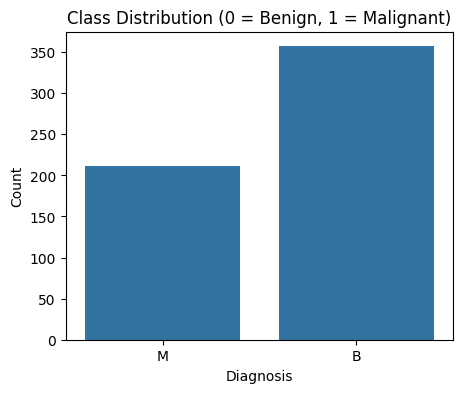

In [21]:
print("Class distribution:\n", df['diagnosis'].value_counts())


plt.figure(figsize=(5,4))
sns.countplot(x='diagnosis', data=df)
plt.title("Class Distribution (0 = Benign, 1 = Malignant)")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

 2. Visualize selected feature distributions

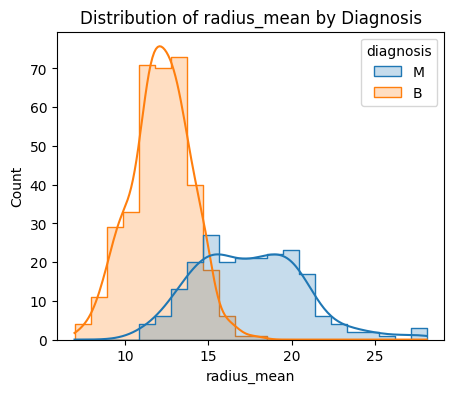

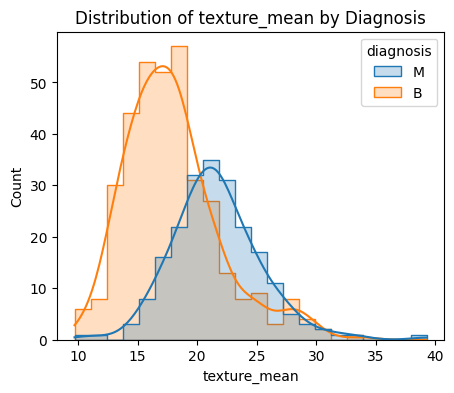

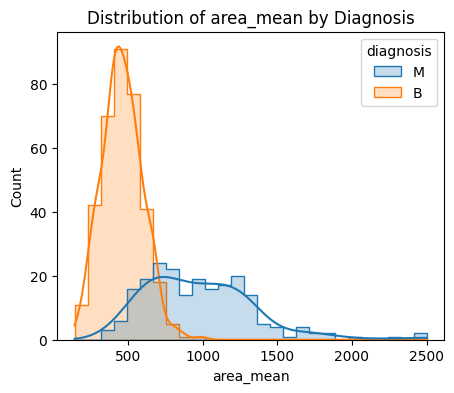

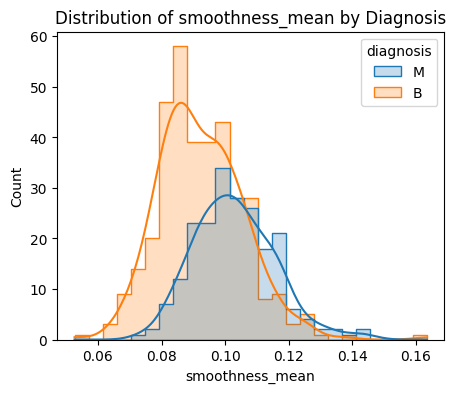

In [22]:
selected_features = ['radius_mean', 'texture_mean', 'area_mean', 'smoothness_mean']

for feature in selected_features:
    plt.figure(figsize=(5,4))
    sns.histplot(data=df, x=feature, hue='diagnosis', kde=True, element='step')
    plt.title(f"Distribution of {feature} by Diagnosis")
    plt.show()

Violin plot and boxplot for a couple of features

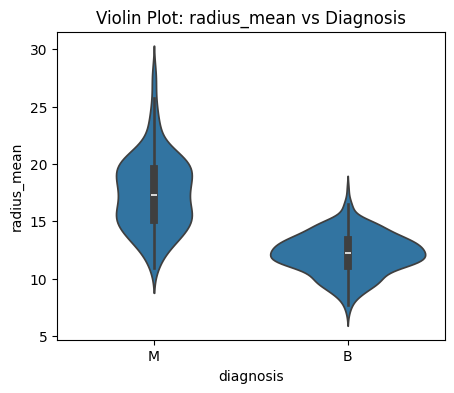

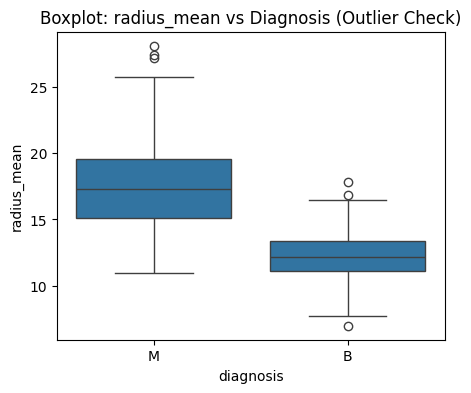

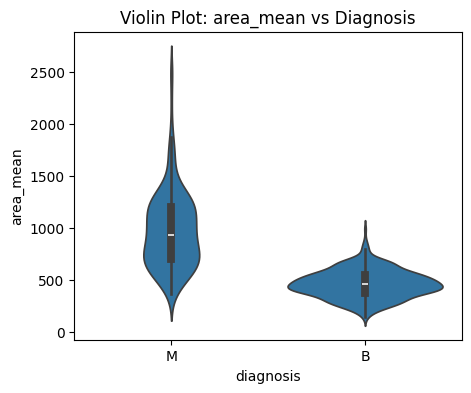

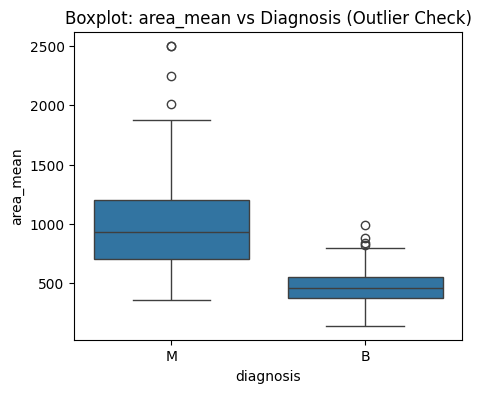

In [23]:
for feature in ['radius_mean', 'area_mean']:
    plt.figure(figsize=(5,4))
    sns.violinplot(x='diagnosis', y=feature, data=df)
    plt.title(f"Violin Plot: {feature} vs Diagnosis")
    plt.show()

    plt.figure(figsize=(5,4))
    sns.boxplot(x='diagnosis', y=feature, data=df)
    plt.title(f"Boxplot: {feature} vs Diagnosis (Outlier Check)")
    plt.show()

3. Inspect relationships among features (pairplot on a few features)

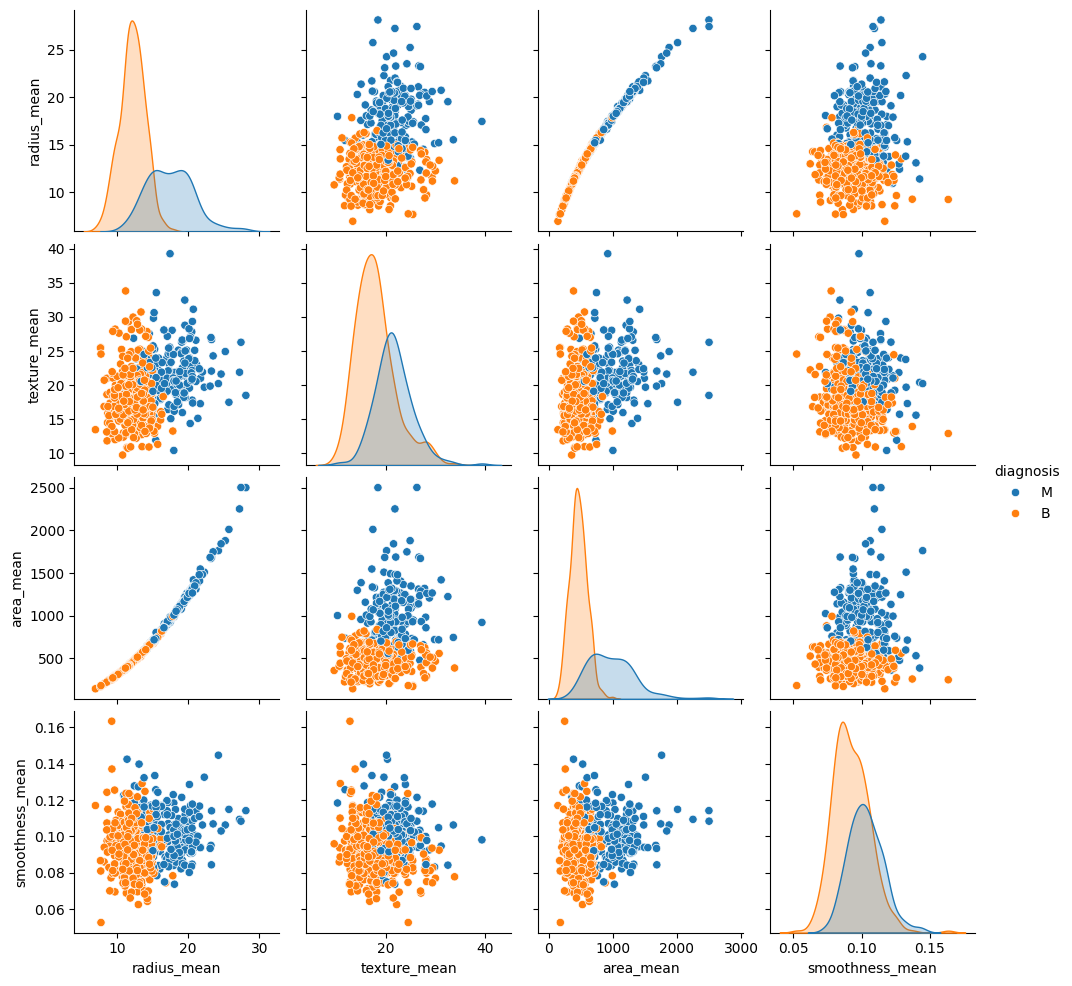

In [24]:
sns.pairplot(df[['radius_mean', 'texture_mean', 'area_mean', 'smoothness_mean', 'diagnosis']],
             hue='diagnosis')
plt.show()


4. Generate correlation matrix and heatmap

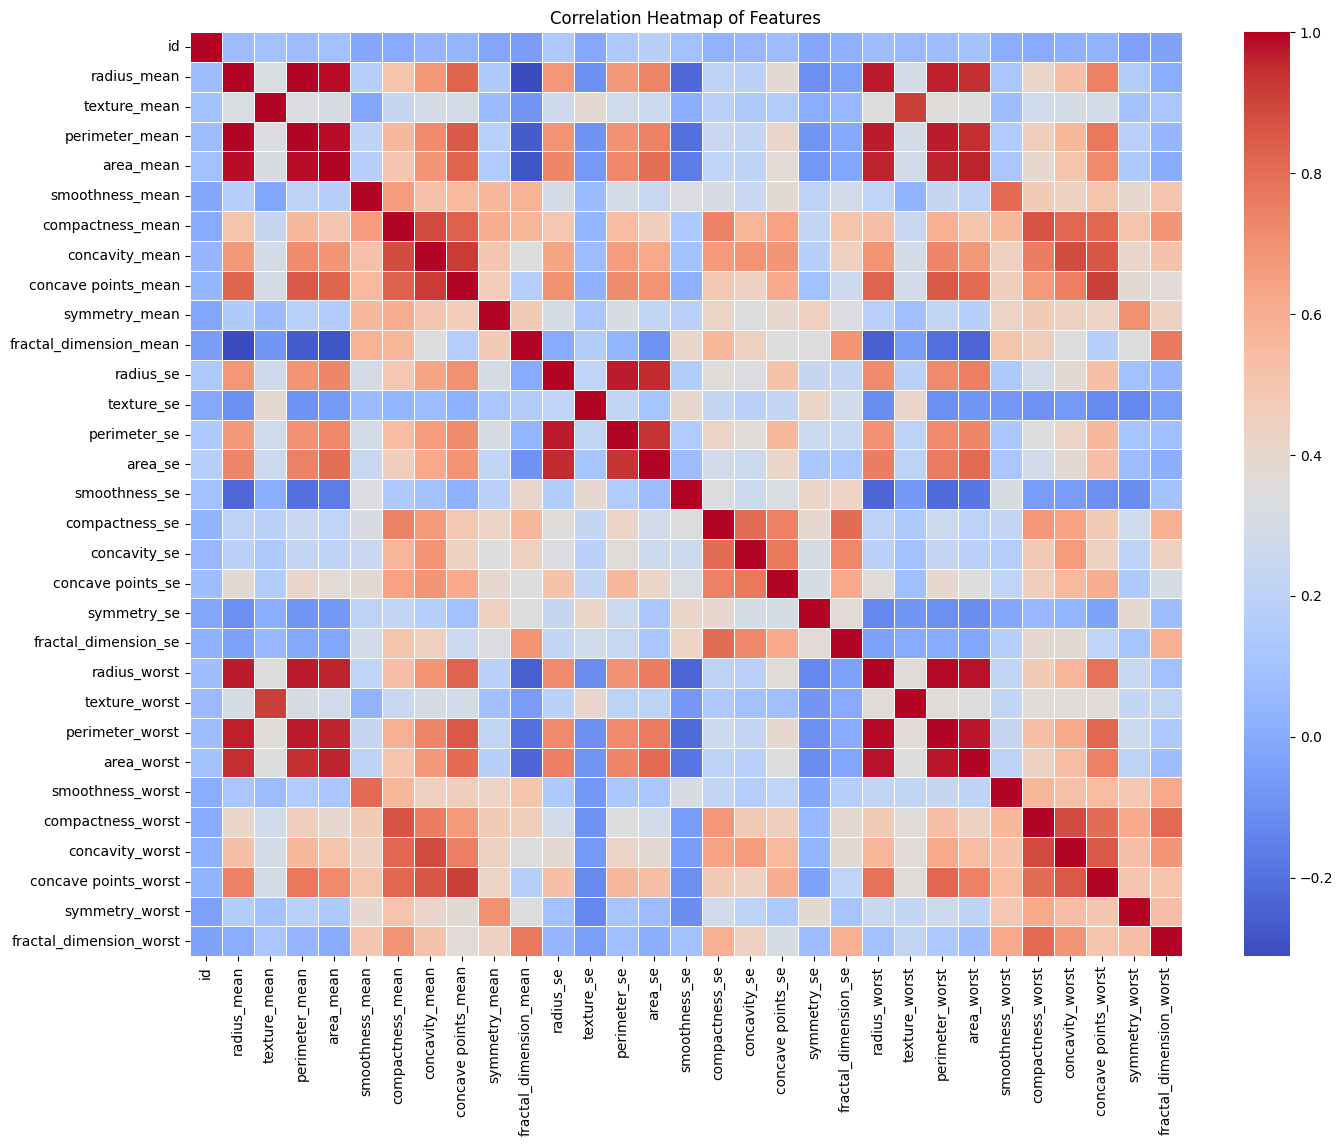

In [25]:
plt.figure(figsize=(16,12))
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

Print top correlated features with diagnosis

In [26]:
# Calculate correlation of features with the encoded target variable
temp_df = df.copy()
temp_df['diagnosis_encoded'] = y_encoded
corr_matrix_with_target = temp_df.corr(numeric_only=True)

print("\nFeatures most correlated with diagnosis:\n")
print(corr_matrix_with_target['diagnosis_encoded'].sort_values(ascending=False))


Features most correlated with diagnosis:

diagnosis_encoded          1.000000
concave points_worst       0.793566
perimeter_worst            0.782914
concave points_mean        0.776614
radius_worst               0.776454
perimeter_mean             0.742636
area_worst                 0.733825
radius_mean                0.730029
area_mean                  0.708984
concavity_mean             0.696360
concavity_worst            0.659610
compactness_mean           0.596534
compactness_worst          0.590998
radius_se                  0.567134
perimeter_se               0.556141
area_se                    0.548236
texture_worst              0.456903
smoothness_worst           0.421465
symmetry_worst             0.416294
texture_mean               0.415185
concave points_se          0.408042
smoothness_mean            0.358560
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_dimension_se 

Step 8: Correlation-Based Feature Selection


In [27]:
import numpy as np


 Calculate correlations among training features (X should already be defined from Step 3)

In [28]:
corr_matrix = X.corr().abs()

Get upper triangle of correlation matrix to avoid duplicate pairs

In [29]:
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

 Identify highly correlated feature pairs (threshold = 0.9)

In [30]:
threshold = 0.9
high_corr_pairs = [
    (col, row, upper_triangle.loc[row, col])
    for col in upper_triangle.columns
    for row in upper_triangle.index
    if pd.notna(upper_triangle.loc[row, col]) and upper_triangle.loc[row, col] > threshold
]

print(f"Highly correlated feature pairs (threshold > {threshold}):")
for col, row, val in high_corr_pairs:
    print(f"{row} - {col} : {val:.2f}")

Highly correlated feature pairs (threshold > 0.9):
radius_mean - perimeter_mean : 1.00
radius_mean - area_mean : 0.99
perimeter_mean - area_mean : 0.99
concavity_mean - concave points_mean : 0.92
radius_se - perimeter_se : 0.97
radius_se - area_se : 0.95
perimeter_se - area_se : 0.94
radius_mean - radius_worst : 0.97
perimeter_mean - radius_worst : 0.97
area_mean - radius_worst : 0.96
texture_mean - texture_worst : 0.91
radius_mean - perimeter_worst : 0.97
perimeter_mean - perimeter_worst : 0.97
area_mean - perimeter_worst : 0.96
radius_worst - perimeter_worst : 0.99
radius_mean - area_worst : 0.94
perimeter_mean - area_worst : 0.94
area_mean - area_worst : 0.96
radius_worst - area_worst : 0.98
perimeter_worst - area_worst : 0.98
concave points_mean - concave points_worst : 0.91


Identify columns to drop (redundant features) based on threshold

In [31]:
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > threshold)]

print(f"\nNumber of redundant features to drop: {len(to_drop)}")
print("Features to drop:\n", to_drop)



Number of redundant features to drop: 10
Features to drop:
 ['perimeter_mean', 'area_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concave points_worst']


Remove redundant features

In [32]:
X_reduced = X.drop(columns=to_drop)

print("\nOriginal feature count:", X.shape[1])
print("Reduced feature count:", X_reduced.shape[1])
print("\nRemaining features:\n", X_reduced.columns.tolist())


Original feature count: 30
Reduced feature count: 20

Remaining features:
 ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'symmetry_worst', 'fractal_dimension_worst']


Step 9: Chi-Square Feature Selection


In [33]:
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.preprocessing import MinMaxScaler


Chi-Square requires non-negative feature values, so scale features to [0, 1] range first

In [34]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_reduced)   # using the reduced feature set from Step 8
X_scaled = pd.DataFrame(X_scaled, columns=X_reduced.columns)


Calculate Chi-Square scores between each feature and the target

In [35]:
chi2_scores, p_values = chi2(X_scaled, y)


Create a DataFrame to rank features according to Chi-Square scores

In [36]:
chi2_results = pd.DataFrame({
    'Feature': X_scaled.columns,
    'Chi2_Score': chi2_scores,
    'P_Value': p_values
}).sort_values(by='Chi2_Score', ascending=False).reset_index(drop=True)

print("Features ranked by Chi-Square score:\n")
print(chi2_results)


Features ranked by Chi-Square score:

                    Feature  Chi2_Score       P_Value
0            concavity_mean   46.186395  1.075210e-11
1           concavity_worst   31.563031  1.930704e-08
2               radius_mean   24.897293  6.046728e-07
3         compactness_worst   20.992541  4.610749e-06
4          compactness_mean   20.353176  6.438614e-06
5                 radius_se   17.324128  3.151598e-05
6              texture_mean    6.394071  1.145021e-02
7         concave points_se    5.781996  1.619115e-02
8          smoothness_worst    5.675733  1.720115e-02
9            symmetry_worst    5.560093  1.837444e-02
10           compactness_se    5.056762  2.453002e-02
11  fractal_dimension_worst    4.410125  3.572622e-02
12            symmetry_mean    3.133130  7.671630e-02
13          smoothness_mean    2.981900  8.420036e-02
14             concavity_se    2.638176  1.043233e-01
15     fractal_dimension_se    0.288034  5.914834e-01
16            smoothness_se    0.146729  7.0

 Select the desired number of high-ranking features (e.g., top 10)

In [37]:
k = 10
selector = SelectKBest(score_func=chi2, k=k)
X_kbest = selector.fit_transform(X_scaled, y)

# Get the selected feature names
selected_features_mask = selector.get_support()
selected_feature_names = X_scaled.columns[selected_features_mask].tolist()

print(f"\nTop {k} features selected by Chi-Square test:\n", selected_feature_names)



Top 10 features selected by Chi-Square test:
 ['radius_mean', 'texture_mean', 'compactness_mean', 'concavity_mean', 'radius_se', 'concave points_se', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'symmetry_worst']


 Final selected feature set as DataFrame

In [38]:
X_chi2_selected = pd.DataFrame(X_kbest, columns=selected_feature_names)
print("\nShape of final selected feature set:", X_chi2_selected.shape)


Shape of final selected feature set: (569, 10)


Step 10: Recursive Feature Elimination (RFE)


In [39]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE


Split data into training and testing sets (using the reduced feature set from Step 8)

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42, stratify=y
)

 Choose an estimator

In [41]:
estimator = LogisticRegression(max_iter=5000)


Set up RFE to select the desired number of features (e.g., top 10)

In [42]:
estimator = LogisticRegression(max_iter=5000)
n_features_to_select = 10
rfe = RFE(estimator=estimator, n_features_to_select=n_features_to_select)

Fit the estimator using the training data

In [43]:
rfe.fit(X_train, y_train)

RFE(estimator=LogisticRegression(max_iter=5000), n_features_to_select=10)

Check which features were selected

In [44]:
selected_mask = rfe.support_
selected_features_rfe = X_train.columns[selected_mask].tolist()

print(f"Selected top {n_features_to_select} features by RFE:\n", selected_features_rfe)


Selected top 10 features by RFE:
 ['radius_mean', 'compactness_mean', 'concavity_mean', 'symmetry_mean', 'radius_se', 'texture_se', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'symmetry_worst']


Rank all features (1 = selected/most important, higher number = eliminated earlier)

In [45]:
feature_ranking = pd.DataFrame({
    'Feature': X_train.columns,
    'Ranking': rfe.ranking_
}).sort_values(by='Ranking').reset_index(drop=True)

print("\nFeature ranking (1 = most important):\n", feature_ranking)



Feature ranking (1 = most important):
                     Feature  Ranking
0               radius_mean        1
1          compactness_mean        1
2             symmetry_mean        1
3            concavity_mean        1
4                 radius_se        1
5                texture_se        1
6          smoothness_worst        1
7         compactness_worst        1
8           concavity_worst        1
9            symmetry_worst        1
10  fractal_dimension_worst        2
11          smoothness_mean        3
12             texture_mean        4
13             concavity_se        5
14           compactness_se        6
15   fractal_dimension_mean        7
16     fractal_dimension_se        8
17        concave points_se        9
18              symmetry_se       10
19            smoothness_se       11


Transform train and test sets to keep only selected features

In [46]:
X_train_rfe = rfe.transform(X_train)
X_test_rfe = rfe.transform(X_test)

print("\nShape after RFE selection:")
print("X_train_rfe:", X_train_rfe.shape)
print("X_test_rfe:", X_test_rfe.shape)


Shape after RFE selection:
X_train_rfe: (455, 10)
X_test_rfe: (114, 10)


 Step 11: Recursive Feature Elimination with Cross-Validation (RFECV)


In [47]:
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression

Choose an estimator

In [48]:
estimator = LogisticRegression(max_iter=5000)


Set up cross-validation strategy

In [49]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Set up RFECV: lets validation performance decide optimal number of features

In [50]:
rfecv = RFECV(
    estimator=estimator,
    step=1,
    cv=cv,
    scoring='accuracy',
    min_features_to_select=1
)

Fit RFECV using the training data

In [51]:
rfecv.fit(X_train, y_train)

RFECV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
      estimator=LogisticRegression(max_iter=5000), scoring='accuracy')

Optimal number of features found

In [52]:
print("Optimal number of features:", rfecv.n_features_)


Optimal number of features: 13


Which features were selected

In [53]:
selected_mask_cv = rfecv.support_
selected_features_rfecv = X_train.columns[selected_mask_cv].tolist()
print("\nSelected features by RFECV:\n", selected_features_rfecv)



Selected features by RFECV:
 ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'symmetry_mean', 'radius_se', 'texture_se', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'symmetry_worst', 'fractal_dimension_worst']


 Feature ranking (1 = selected)

In [54]:
feature_ranking_cv = pd.DataFrame({
    'Feature': X_train.columns,
    'Ranking': rfecv.ranking_
}).sort_values(by='Ranking').reset_index(drop=True)
print("\nFeature ranking:\n", feature_ranking_cv)


Feature ranking:
                     Feature  Ranking
0               radius_mean        1
1              texture_mean        1
2           smoothness_mean        1
3          compactness_mean        1
4            concavity_mean        1
5             symmetry_mean        1
6                 radius_se        1
7                texture_se        1
8          smoothness_worst        1
9            symmetry_worst        1
10          concavity_worst        1
11        compactness_worst        1
12  fractal_dimension_worst        1
13             concavity_se        2
14           compactness_se        3
15   fractal_dimension_mean        4
16     fractal_dimension_se        5
17        concave points_se        6
18              symmetry_se        7
19            smoothness_se        8


Plot number of features vs cross-validation score

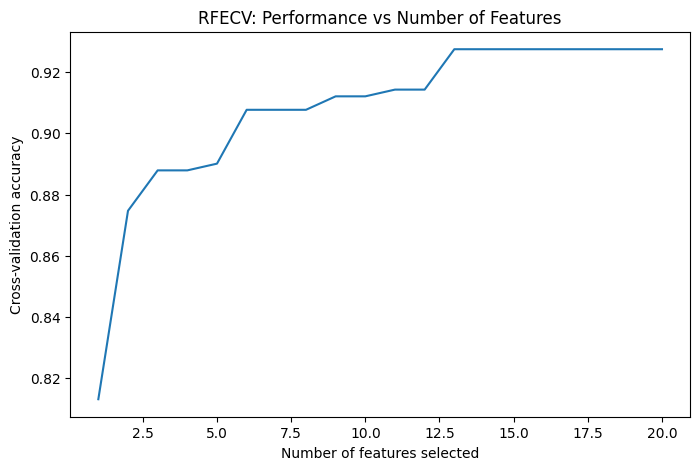

In [55]:
import matplotlib.pyplot as plt

cv_results = rfecv.cv_results_
plt.figure(figsize=(8,5))
plt.xlabel("Number of features selected")
plt.ylabel("Cross-validation accuracy")
plt.plot(range(1, len(cv_results['mean_test_score']) + 1), cv_results['mean_test_score'])
plt.title("RFECV: Performance vs Number of Features")
plt.show()

Transform train and test sets to keep only RFECV-selected features

In [56]:
X_train_rfecv = rfecv.transform(X_train)
X_test_rfecv = rfecv.transform(X_test)

print("\nShape after RFECV selection:")
print("X_train_rfecv:", X_train_rfecv.shape)
print("X_test_rfecv:", X_test_rfecv.shape)


Shape after RFECV selection:
X_train_rfecv: (455, 13)
X_test_rfecv: (114, 13)


Step 12: Random Forest Feature Importance

In [57]:

from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

Train a Random Forest classifier using the training data

In [58]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

Extract feature-importance scores

In [59]:
importances = rf_model.feature_importances_

 Rank features according to importance

In [60]:
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("Feature importance ranking:\n", feature_importance_df)

Feature importance ranking:
                     Feature  Importance
0               radius_mean    0.222840
1            concavity_mean    0.149035
2           concavity_worst    0.133187
3                 radius_se    0.083215
4          compactness_mean    0.071926
5         compactness_worst    0.054631
6              texture_mean    0.037014
7              concavity_se    0.036140
8            symmetry_worst    0.033191
9           smoothness_mean    0.026457
10         smoothness_worst    0.023201
11     fractal_dimension_se    0.019040
12   fractal_dimension_mean    0.018419
13        concave points_se    0.017674
14           compactness_se    0.015244
15              symmetry_se    0.014283
16  fractal_dimension_worst    0.012455
17            smoothness_se    0.012359
18            symmetry_mean    0.010014
19               texture_se    0.009675


 Visualize feature importances

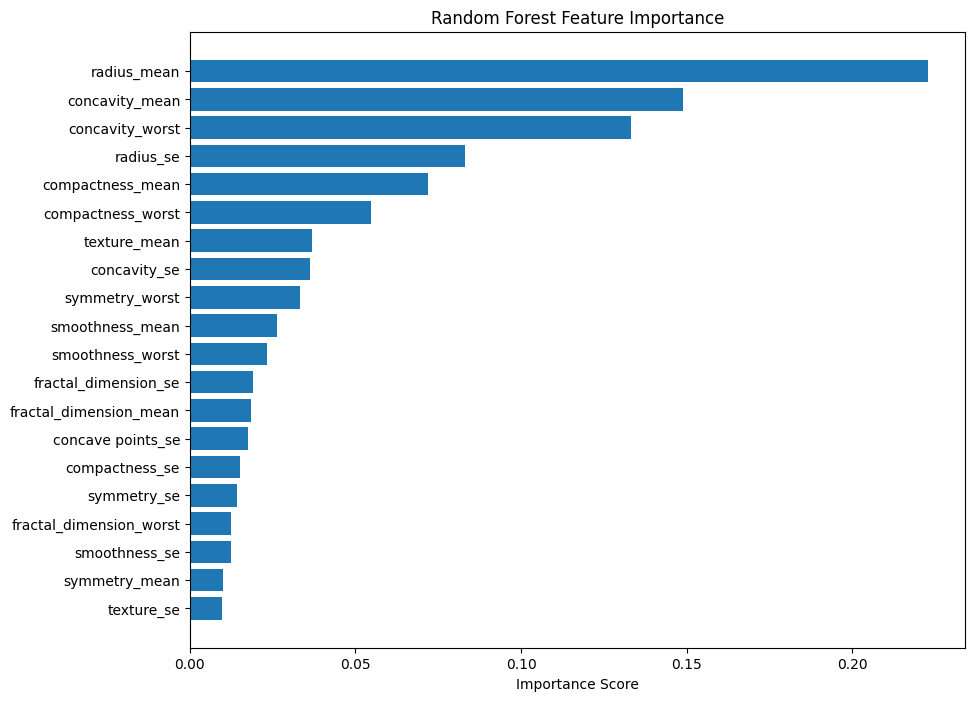

In [61]:
plt.figure(figsize=(10,8))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
plt.gca().invert_yaxis()
plt.xlabel("Importance Score")
plt.title("Random Forest Feature Importance")
plt.show()

Retain an appropriate subset (e.g., top 10 features)

In [62]:
k = 10
top_features_rf = feature_importance_df['Feature'].head(k).tolist()
print(f"\nTop {k} features selected by Random Forest:\n", top_features_rf)


Top 10 features selected by Random Forest:
 ['radius_mean', 'concavity_mean', 'concavity_worst', 'radius_se', 'compactness_mean', 'compactness_worst', 'texture_mean', 'concavity_se', 'symmetry_worst', 'smoothness_mean']


Create reduced training/testing sets with only the selected features

In [63]:
X_train_rf = X_train[top_features_rf]
X_test_rf = X_test[top_features_rf]

print("\nShape after Random Forest feature selection:")
print("X_train_rf:", X_train_rf.shape)
print("X_test_rf:", X_test_rf.shape)


Shape after Random Forest feature selection:
X_train_rf: (455, 10)
X_test_rf: (114, 10)


Step 13: Extra Trees Feature Importance

In [64]:

from sklearn.ensemble import ExtraTreesClassifier
import matplotlib.pyplot as plt

Train an Extra Trees classifier using the training data

In [65]:
et_model = ExtraTreesClassifier(n_estimators=200, random_state=42)
et_model.fit(X_train, y_train)

ExtraTreesClassifier(n_estimators=200, random_state=42)

Extract feature-importance scores


In [67]:
et_importances = et_model.feature_importances_

Rank features according to importance

In [68]:
et_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': et_importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("Extra Trees feature importance ranking:\n", et_importance_df)

Extra Trees feature importance ranking:
                     Feature  Importance
0               radius_mean    0.167952
1            concavity_mean    0.140336
2           concavity_worst    0.109874
3                 radius_se    0.092280
4          compactness_mean    0.069959
5         compactness_worst    0.060880
6              texture_mean    0.051795
7            symmetry_worst    0.038673
8          smoothness_worst    0.036746
9           smoothness_mean    0.028302
10   fractal_dimension_mean    0.024980
11           compactness_se    0.024046
12             concavity_se    0.024016
13        concave points_se    0.023360
14  fractal_dimension_worst    0.020436
15     fractal_dimension_se    0.019087
16            symmetry_mean    0.018605
17              symmetry_se    0.018334
18            smoothness_se    0.017591
19               texture_se    0.012748


Visualize feature importances

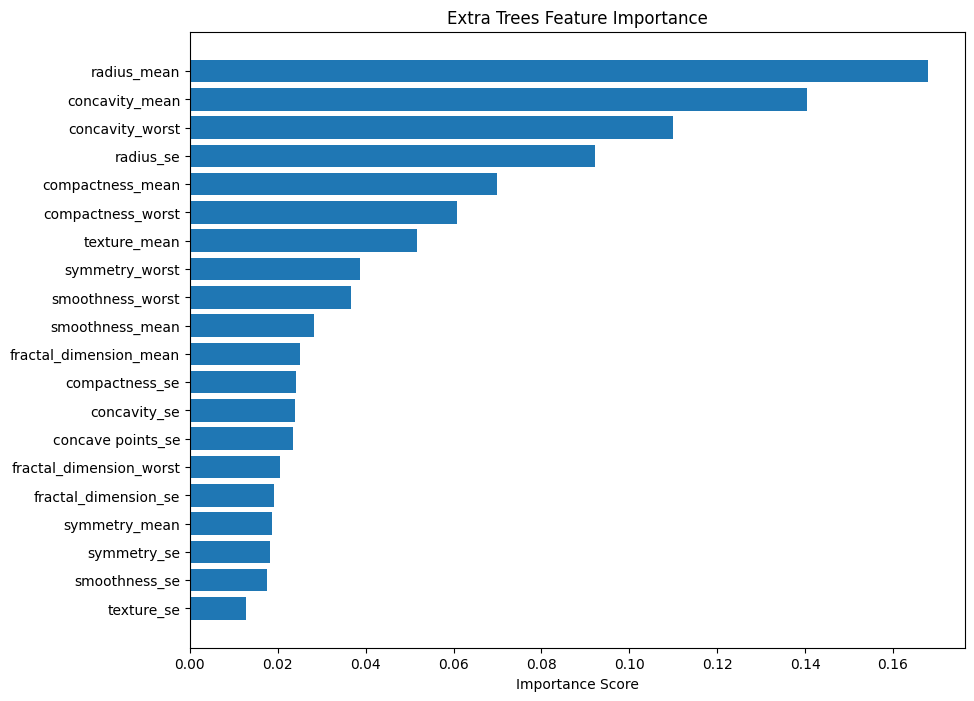

In [69]:
plt.figure(figsize=(10,8))
plt.barh(et_importance_df['Feature'], et_importance_df['Importance'])
plt.gca().invert_yaxis()
plt.xlabel("Importance Score")
plt.title("Extra Trees Feature Importance")
plt.show()

 Select the top-k features (e.g., top 10)

In [70]:
k = 10
top_features_et = et_importance_df['Feature'].head(k).tolist()
print(f"\nTop {k} features selected by Extra Trees:\n", top_features_et)


Top 10 features selected by Extra Trees:
 ['radius_mean', 'concavity_mean', 'concavity_worst', 'radius_se', 'compactness_mean', 'compactness_worst', 'texture_mean', 'symmetry_worst', 'smoothness_worst', 'smoothness_mean']


Create reduced training/testing sets with only the selected features

In [71]:
X_train_et = X_train[top_features_et]
X_test_et = X_test[top_features_et]

print("\nShape after Extra Trees feature selection:")
print("X_train_et:", X_train_et.shape)
print("X_test_et:", X_test_et.shape)


Shape after Extra Trees feature selection:
X_train_et: (455, 10)
X_test_et: (114, 10)


Optional: compare Random Forest and Extra Trees top features

In [73]:
common_features = set(top_features_rf).intersection(set(top_features_et))
print("\nCommon top features in both Random Forest and Extra Trees:\n", list(common_features))


Common top features in both Random Forest and Extra Trees:
 ['compactness_mean', 'smoothness_mean', 'texture_mean', 'radius_se', 'radius_mean', 'compactness_worst', 'symmetry_worst', 'concavity_mean', 'concavity_worst']


Step 14: L1-Based Feature Selection

In [74]:

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

Scale features (fit on training data only to avoid data leakage)

In [75]:
scaler_l1 = StandardScaler()
X_train_scaled = pd.DataFrame(scaler_l1.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler_l1.transform(X_test), columns=X_test.columns, index=X_test.index)

Fit an L1-regularized Logistic Regression model using training data

In [76]:
l1_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42)
l1_model.fit(X_train_scaled, y_train)


LogisticRegression(C=0.1, penalty='l1', random_state=42, solver='liblinear')

Examine coefficients

In [78]:
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': l1_model.coef_[0]
})
coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(by='Abs_Coefficient', ascending=False).reset_index(drop=True)

print("L1 model coefficients:\n", coef_df)

L1 model coefficients:
                     Feature  Coefficient  Abs_Coefficient
0               radius_mean     2.312730         2.312730
1          smoothness_worst     0.706597         0.706597
2                 radius_se     0.666863         0.666863
3              texture_mean     0.549283         0.549283
4            symmetry_worst     0.484321         0.484321
5           concavity_worst     0.455736         0.455736
6            concavity_mean     0.052996         0.052996
7           smoothness_mean     0.000000         0.000000
8          compactness_mean     0.000000         0.000000
9                texture_se     0.000000         0.000000
10            symmetry_mean     0.000000         0.000000
11   fractal_dimension_mean     0.000000         0.000000
12             concavity_se     0.000000         0.000000
13           compactness_se     0.000000         0.000000
14            smoothness_se     0.000000         0.000000
15        concave points_se     0.000000        

Visualize coefficients

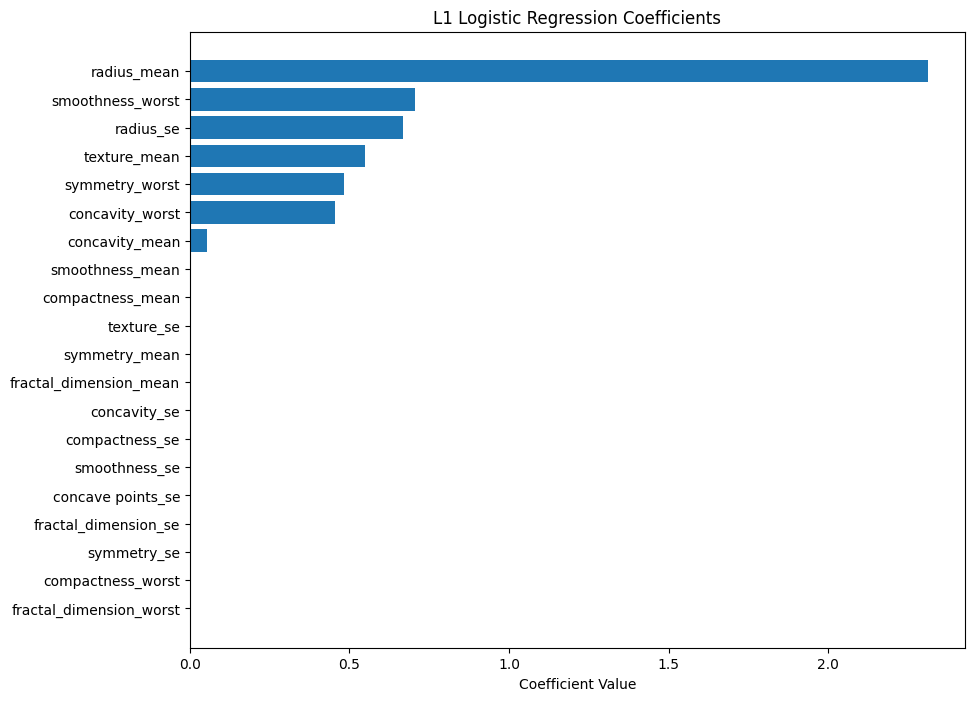

In [79]:
plt.figure(figsize=(10,8))
plt.barh(coef_df['Feature'], coef_df['Coefficient'])
plt.gca().invert_yaxis()
plt.xlabel("Coefficient Value")
plt.title("L1 Logistic Regression Coefficients")
plt.show()

Identify features with non-zero coefficients using SelectFromModel

In [80]:
selector_l1 = SelectFromModel(l1_model, prefit=True)
selected_mask_l1 = selector_l1.get_support()
selected_features_l1 = X_train.columns[selected_mask_l1].tolist()

print(f"\nNumber of features with non-zero coefficients: {len(selected_features_l1)}")
print("Selected features by L1:\n", selected_features_l1)

zero_features = X_train.columns[~selected_mask_l1].tolist()
print("\nFeatures shrunk to zero (removed):\n", zero_features)


Number of features with non-zero coefficients: 7
Selected features by L1:
 ['radius_mean', 'texture_mean', 'concavity_mean', 'radius_se', 'smoothness_worst', 'concavity_worst', 'symmetry_worst']

Features shrunk to zero (removed):
 ['smoothness_mean', 'compactness_mean', 'symmetry_mean', 'fractal_dimension_mean', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'compactness_worst', 'fractal_dimension_worst']


Retain the selected subset

In [81]:
X_train_l1 = X_train_scaled[selected_features_l1]
X_test_l1 = X_test_scaled[selected_features_l1]

print("\nShape after L1 feature selection:")
print("X_train_l1:", X_train_l1.shape)
print("X_test_l1:", X_test_l1.shape)


Shape after L1 feature selection:
X_train_l1: (455, 7)
X_test_l1: (114, 7)


 Step 15: Voting-Based Feature Selection

In [82]:
import pandas as pd
import matplotlib.pyplot as plt

All candidate features (the reduced set after Step 8 correlation filtering)

In [83]:
all_features = X_train.columns.tolist()

Selected features from each feature-selection method

In [84]:
selection_results = {
    'Chi2':          selected_feature_names,     # Step 9
    'RFE':           selected_features_rfe,      # Step 10
    'RFECV':         selected_features_rfecv,    # Step 11
    'RandomForest':  top_features_rf,            # Step 12
    'ExtraTrees':    top_features_et,            # Step 13
    'L1':            selected_features_l1        # Step 14
}

Record whether each feature is selected by each method (1 = selected, 0 = not selected)

In [85]:
votes_df = pd.DataFrame(index=all_features)

for method, selected in selection_results.items():
    votes_df[method] = [1 if feature in selected else 0 for feature in all_features]

Calculate total votes for each feature

In [87]:
votes_df['Total_Votes'] = votes_df.sum(axis=1)

Rank features according to total votes

In [88]:
votes_df = votes_df.sort_values(by='Total_Votes', ascending=False)

print("Voting table:\n")
print(votes_df)

Voting table:

                         Chi2  RFE  RFECV  RandomForest  ExtraTrees  L1  \
radius_mean                 1    1      1             1           1   1   
concavity_worst             1    1      1             1           1   1   
radius_se                   1    1      1             1           1   1   
concavity_mean              1    1      1             1           1   1   
symmetry_worst              1    1      1             1           1   1   
compactness_worst           1    1      1             1           1   0   
texture_mean                1    0      1             1           1   1   
compactness_mean            1    1      1             1           1   0   
smoothness_worst            1    1      1             0           1   1   
smoothness_mean             0    0      1             1           1   0   
symmetry_mean               0    1      1             0           0   0   
texture_se                  0    1      1             0           0   0   
concave po

Visualize total votes

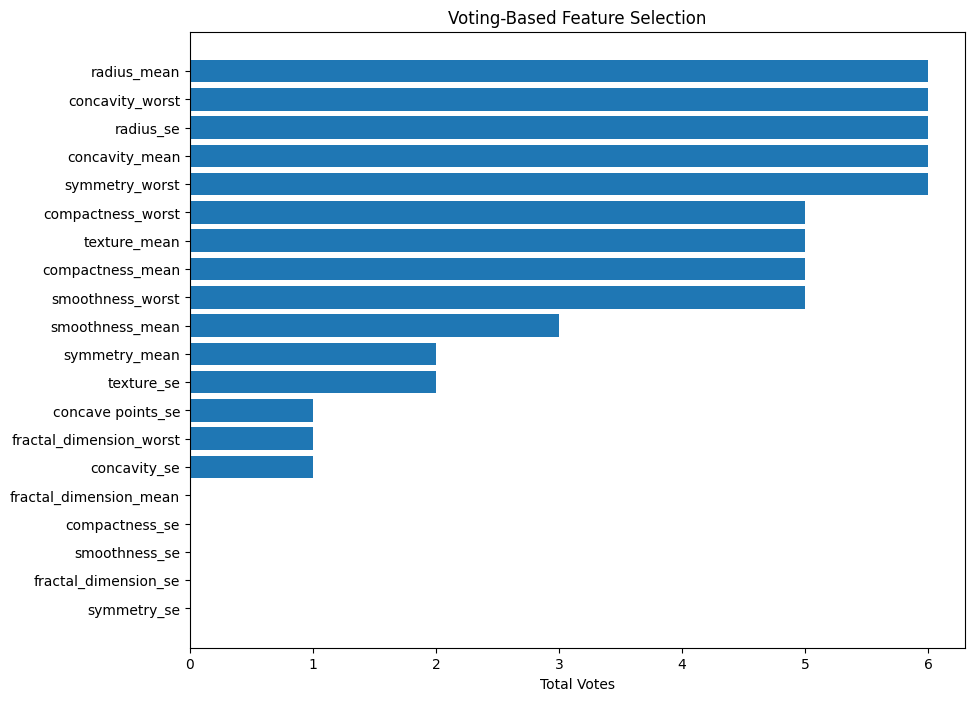

In [89]:
plt.figure(figsize=(10,8))
plt.barh(votes_df.index, votes_df['Total_Votes'])
plt.gca().invert_yaxis()
plt.xlabel("Total Votes")
plt.title("Voting-Based Feature Selection")
plt.show()

Select the most consistently supported features
 (selected by at least half of the methods, i.e., 3 out of 6)

In [90]:
vote_threshold = 3
final_selected_features = votes_df[votes_df['Total_Votes'] >= vote_threshold].index.tolist()

print(f"\nFeatures selected by at least {vote_threshold} methods ({len(final_selected_features)} features):\n")
print(final_selected_features)


Features selected by at least 3 methods (10 features):

['radius_mean', 'concavity_worst', 'radius_se', 'concavity_mean', 'symmetry_worst', 'compactness_worst', 'texture_mean', 'compactness_mean', 'smoothness_worst', 'smoothness_mean']


 Create final reduced training/testing sets

In [91]:
X_train_final = X_train[final_selected_features]
X_test_final = X_test[final_selected_features]

print("\nShape of final feature sets:")
print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)


Shape of final feature sets:
X_train_final: (455, 10)
X_test_final: (114, 10)


Step 16: Construct Feature-Selected Datasets

In [92]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler

 Re-do Chi-Square selection using TRAINING data only (fixes the leakage from Step 9,
 where the scaler and selector were fit on the full dataset)

In [99]:
mm_scaler = MinMaxScaler()
X_train_mm = mm_scaler.fit_transform(X_train)
chi2_selector = SelectKBest(score_func=chi2, k=10).fit(X_train_mm, y_train)
selected_features_chi2 = X_train.columns[chi2_selector.get_support()].tolist()

Dictionary of selected feature lists for every strategy

In [95]:
feature_sets = {
    'All_Features':  X_train.columns.tolist(),   # baseline (no selection)
    'Chi2':          selected_features_chi2,     # Step 9 (retrained on train only)
    'RFE':           selected_features_rfe,      # Step 10
    'RFECV':         selected_features_rfecv,    # Step 11
    'RandomForest':  top_features_rf,            # Step 12
    'ExtraTrees':    top_features_et,            # Step 13
    'L1':            selected_features_l1,       # Step 14
    'Voting':        final_selected_features     # Step 15
}

Build train and test matrices for each strategy using the SAME columns in the SAME order

In [96]:
train_sets = {}
test_sets = {}

for name, features in feature_sets.items():
    train_sets[name] = X_train.loc[:, features]
    test_sets[name]  = X_test.loc[:, features]

 Sanity checks

In [100]:
  assert list(train_sets[name].columns) == list(test_sets[name].columns), \
        f"Feature order mismatch in {name}"

Summary

In [101]:
summary = pd.DataFrame({
    'Strategy': list(feature_sets.keys()),
    'N_Features': [len(f) for f in feature_sets.values()],
    'Train_Shape': [train_sets[n].shape for n in feature_sets],
    'Test_Shape': [test_sets[n].shape for n in feature_sets]
})
print(summary)

       Strategy  N_Features Train_Shape Test_Shape
0  All_Features          20   (455, 20)  (114, 20)
1          Chi2          10   (455, 10)  (114, 10)
2           RFE          10   (455, 10)  (114, 10)
3         RFECV          13   (455, 13)  (114, 13)
4  RandomForest          10   (455, 10)  (114, 10)
5    ExtraTrees          10   (455, 10)  (114, 10)
6            L1           7    (455, 7)   (114, 7)
7        Voting          10   (455, 10)  (114, 10)


Example: inspect one dataset

In [102]:
print("\nVoting-based train features:\n", train_sets['Voting'].columns.tolist())
train_sets['Voting'].head()


Voting-based train features:
 ['radius_mean', 'concavity_worst', 'radius_se', 'concavity_mean', 'symmetry_worst', 'compactness_worst', 'texture_mean', 'compactness_mean', 'smoothness_worst', 'smoothness_mean']


,radius_mean,concavity_worst,radius_se,concavity_mean,symmetry_worst,compactness_worst,texture_mean,compactness_mean,smoothness_worst,smoothness_mean
10,16.02,0.1459,0.3795,0.03299,0.2948,0.1551,23.24,0.06669,0.11810,0.08206
170,12.32,0.1242,0.2360,0.03987,0.2827,0.1266,12.39,0.06981,0.13850,0.10280
407,12.85,0.1838,0.4993,0.06126,0.2488,0.1936,21.37,0.08316,0.09402,0.07551
430,14.90,0.9019,0.2530,0.27330,0.2866,0.7090,22.53,0.22250,0.14190,0.09947
27,18.61,0.3446,0.8529,0.14900,0.2341,0.2117,20.25,0.10660,0.13380,0.09440


Step 17: Train Supervised Machine-Learning Models

In [103]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

Define the models (scale-sensitive models are wrapped with StandardScaler)

In [104]:
def get_models():
    return {
        'Logistic Regression': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=5000, random_state=42))
        ]),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
        'SVM': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVC(kernel='rbf', probability=True, random_state=42))
        ]),
        'Extra Trees': ExtraTreesClassifier(n_estimators=200, random_state=42),
        'KNN': Pipeline([
            ('scaler', StandardScaler()),
            ('model', KNeighborsClassifier(n_neighbors=5))
        ]),
        'Decision Tree': DecisionTreeClassifier(random_state=42),
        'Naive Bayes': GaussianNB()
    }

Train every model on every feature-selected training set

In [105]:
trained_models = {}   # structure: trained_models[feature_set_name][model_name]

for fs_name, X_tr in train_sets.items():
    trained_models[fs_name] = {}
    models = get_models()   # fresh, untrained models for each feature set

    for model_name, model in models.items():
        model.fit(X_tr, y_train)
        trained_models[fs_name][model_name] = model

    print(f"Trained {len(models)} models on feature set: {fs_name} ({X_tr.shape[1]} features)")

print("\nTotal models trained:", sum(len(m) for m in trained_models.values()))

Trained 7 models on feature set: All_Features (20 features)
Trained 7 models on feature set: Chi2 (10 features)
Trained 7 models on feature set: RFE (10 features)
Trained 7 models on feature set: RFECV (13 features)
Trained 7 models on feature set: RandomForest (10 features)
Trained 7 models on feature set: ExtraTrees (10 features)
Trained 7 models on feature set: L1 (7 features)
Trained 7 models on feature set: Voting (10 features)

Total models trained: 56


Step 18: Hyperparameter Optimization

In [107]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold

Cross-validation strategy (applied on training data only)

In [108]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

 Define candidate hyperparameter values for each model
 (Pipeline models use the 'model__' prefix)

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import SelectKBest, chi2, RFE, RFECV

# 1. Ensure core data and targets are loaded if state was lost
if 'df' not in locals() and 'df' not in globals():
    df = pd.read_csv('/content/data.csv')
    df = df.drop(columns=['Unnamed: 32'], errors='ignore')

y = df['diagnosis']
X = df.drop(columns=['id', 'diagnosis'])
X = X.fillna(X.mean())

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Remove highly correlated features (> 0.9) to match original workflow steps
corr_matrix = X.corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]
X_reduced = X.drop(columns=to_drop)

# 2. Re-create train/test splits
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 3. Re-generate selected feature sets from each strategy
# Chi2
mm_scaler = MinMaxScaler()
X_train_mm = mm_scaler.fit_transform(X_train)
chi2_selector = SelectKBest(score_func=chi2, k=10).fit(X_train_mm, y_train)
selected_features_chi2 = X_train.columns[chi2_selector.get_support()].tolist()

# RFE
rfe = RFE(estimator=LogisticRegression(max_iter=5000), n_features_to_select=10)
rfe.fit(X_train, y_train)
selected_features_rfe = X_train.columns[rfe.support_].tolist()

# RFECV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rfecv = RFECV(estimator=LogisticRegression(max_iter=5000), step=1, cv=cv, scoring='accuracy', min_features_to_select=1)
rfecv.fit(X_train, y_train)
selected_features_rfecv = X_train.columns[rfecv.support_].tolist()

# RandomForest
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
importances = rf_model.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances}).sort_values(by='Importance', ascending=False)
top_features_rf = feature_importance_df['Feature'].head(10).tolist()

# ExtraTrees
et_model = ExtraTreesClassifier(n_estimators=200, random_state=42)
et_model.fit(X_train, y_train)
top_features_et = pd.DataFrame({'Feature': X_train.columns, 'Importance': et_model.feature_importances_}).sort_values(by='Importance', ascending=False)['Feature'].head(10).tolist()

# L1
l1_scaler = StandardScaler()
X_train_scaled = l1_scaler.fit_transform(X_train)
l1_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42).fit(X_train_scaled, y_train)
selected_features_l1 = X_train.columns[l1_model.coef_[0] != 0].tolist()

# Voting
votes_df = pd.DataFrame(index=X_train.columns.tolist())
selection_results = {
    'Chi2': selected_features_chi2,
    'RFE': selected_features_rfe,
    'RFECV': selected_features_rfecv,
    'RandomForest': top_features_rf,
    'ExtraTrees': top_features_et,
    'L1': selected_features_l1
}
for method, selected in selection_results.items():
    votes_df[method] = [1 if f in selected else 0 for f in votes_df.index]
votes_df['Total_Votes'] = votes_df.sum(axis=1)
final_selected_features = votes_df[votes_df['Total_Votes'] >= 3].index.tolist()

# 4. Define the 8 feature sets
train_sets = {
    'All_Features':  X_train,
    'Chi2':          X_train[selected_features_chi2],
    'RFE':           X_train[selected_features_rfe],
    'RFECV':         X_train[selected_features_rfecv],
    'RandomForest':  X_train[top_features_rf],
    'ExtraTrees':    X_train[top_features_et],
    'L1':            X_train[selected_features_l1],
    'Voting':        X_train[final_selected_features]
}

def get_models():
    return {
        'Logistic Regression': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=5000, random_state=42))
        ]),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
        'SVM': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVC(kernel='rbf', probability=True, random_state=42))
        ]),
        'Extra Trees': ExtraTreesClassifier(n_estimators=200, random_state=42),
        'KNN': Pipeline([
            ('scaler', StandardScaler()),
            ('model', KNeighborsClassifier(n_neighbors=5))
        ]),
        'Decision Tree': DecisionTreeClassifier(random_state=42),
        'Naive Bayes': GaussianNB()
    }

param_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__penalty': ['l1', 'l2'],
        'model__solver': ['liblinear']
    },
    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5]
    },
    'SVM': {
        'model__C': [0.1, 1, 10],
        'model__gamma': ['scale', 0.01, 0.1],
        'model__kernel': ['rbf']
    },
    'Extra Trees': {
        'n_estimators': [100, 200],
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5]
    },
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 9, 11],
        'model__weights': ['uniform', 'distance'],
        'model__metric': ['euclidean', 'manhattan']
    },
    'Decision Tree': {
        'max_depth': [3, 5, 7, None],
        'min_samples_split': [2, 5, 10],
        'criterion': ['gini', 'entropy']
    },
    'Naive Bayes': {
        'var_smoothing': np.logspace(-9, -5, 5)
    }
}

tuned_models = {}      # tuned_models[feature_set][model_name] -> refitted best estimator
results = []           # summary of best CV score and parameters

for fs_name, X_tr in train_sets.items():
    tuned_models[fs_name] = {}
    models = get_models()   # fresh untrained models

    for model_name, model in models.items():
        grid = GridSearchCV(
            estimator=model,
            param_grid=param_grids[model_name],
            cv=cv,
            scoring='accuracy',
            n_jobs=-1,
            refit=True          # refit best configuration on the full training set
        )
        grid.fit(X_tr, y_train)

        # Save results directly within the loop
        tuned_models[fs_name][model_name] = grid.best_estimator_
        results.append({
            'Feature_Set': fs_name,
            'Model': model_name,
            'Best_CV_Accuracy': grid.best_score_,
            'Best_Params': grid.best_params_
        })

    print(f"Finished tuning all models for feature set: {fs_name}")

Finished tuning all models for feature set: All_Features
Finished tuning all models for feature set: Chi2
Finished tuning all models for feature set: RFE
Finished tuning all models for feature set: RFECV
Finished tuning all models for feature set: RandomForest
Finished tuning all models for feature set: ExtraTrees
Finished tuning all models for feature set: L1
Finished tuning all models for feature set: Voting


Final model refitted with the best configuration

In [13]:
# Since cell fN7nc6Ok5zb7 ran successfully, all grid search results are already saved.
# We can convert the 'results' list into a clean, sorted DataFrame to analyze the performance.
results_df = pd.DataFrame(results)

# Sort by Best_CV_Accuracy descending to find the top configurations
results_df = results_df.sort_values(by='Best_CV_Accuracy', ascending=False).reset_index(drop=True)

print("Top 15 Hyperparameter-Tuned Model Configurations:")
results_df.head(15)

Top 15 Hyperparameter-Tuned Model Configurations:


,Feature_Set,Model,Best_CV_Accuracy,Best_Params
0,Voting,SVM,0.978022,"{'model__C': 10, 'model__gamma': 0.01, 'model_..."
1,ExtraTrees,SVM,0.978022,"{'model__C': 10, 'model__gamma': 0.01, 'model_..."
2,Chi2,Logistic Regression,0.975824,"{'model__C': 1, 'model__penalty': 'l1', 'model..."
3,All_Features,SVM,0.975824,"{'model__C': 10, 'model__gamma': 0.01, 'model_..."
4,L1,SVM,0.973626,"{'model__C': 10, 'model__gamma': 0.01, 'model_..."
5,L1,Logistic Regression,0.973626,"{'model__C': 1, 'model__penalty': 'l2', 'model..."
6,RFECV,Logistic Regression,0.973626,"{'model__C': 1, 'model__penalty': 'l2', 'model..."
7,Chi2,SVM,0.973626,"{'model__C': 10, 'model__gamma': 0.01, 'model_..."
8,RFECV,SVM,0.971429,"{'model__C': 10, 'model__gamma': 0.01, 'model_..."
9,Voting,Logistic Regression,0.971429,"{'model__C': 1, 'model__penalty': 'l2', 'model..."


Summary table of results

In [16]:
tuning_results = pd.DataFrame(results).sort_values(by='Best_CV_Accuracy', ascending=False).reset_index(drop=True)

print("\nTop 10 configurations by cross-validation accuracy:\n")
print(tuning_results.head(10).to_string())

# Best configuration for each model (across feature sets)
best_per_model = tuning_results.loc[tuning_results.groupby('Model')['Best_CV_Accuracy'].idxmax()]
print("\nBest configuration per model:\n")
print(best_per_model[['Model', 'Feature_Set', 'Best_CV_Accuracy', 'Best_Params']].to_string(index=False))


Top 10 configurations by cross-validation accuracy:

    Feature_Set                Model  Best_CV_Accuracy                                                            Best_Params
0        Voting                  SVM          0.978022         {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
1    ExtraTrees                  SVM          0.978022         {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
2          Chi2  Logistic Regression          0.975824  {'model__C': 1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
3  All_Features                  SVM          0.975824         {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
4            L1                  SVM          0.973626         {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
5            L1  Logistic Regression          0.973626  {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}
6         RFECV  Logistic Regression          0.973626  {'model_

 Step 19: Generate Test Predictions

In [19]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd

# Define the top models to evaluate on the test set based on cross-validation results
top_evaluations = [
    ('Voting', 'SVM'),
    ('ExtraTrees', 'SVM'),
    ('Chi2', 'Logistic Regression')
]

test_results = []

for fs_name, model_name in top_evaluations:
    # Retrieve the best estimator
    model = tuned_models[fs_name][model_name]

    # Get the appropriate test features
    X_te = test_sets[fs_name]

    # Predict
    y_pred = model.predict(X_te)

    # Calculate score
    test_acc = accuracy_score(y_test, y_pred)

    test_results.append({
        'Feature_Set': fs_name,
        'Model': model_name,
        'Test_Accuracy': test_acc,
        'Classification_Report': classification_report(y_test, y_pred, output_dict=True)
    })

# Convert results to DataFrame for display
test_results_df = pd.DataFrame(test_results)
print("Test Set Performance of Top Tuned Models:")
display(test_results_df[['Feature_Set', 'Model', 'Test_Accuracy']])

Test Set Performance of Top Tuned Models:


,Feature_Set,Model,Test_Accuracy
0,Voting,SVM,0.973684
1,ExtraTrees,SVM,0.973684
2,Chi2,Logistic Regression,0.973684


In [21]:
predictions = {}

# Loop over all feature selection strategies and tuned models to gather predictions
for fs_name, models_dict in tuned_models.items():
    predictions[fs_name] = {}
    X_te = test_sets[fs_name]

    for model_name, model in models_dict.items():
        # Predict diagnosis labels (0 = Benign, 1 = Malignant)
        y_pred = model.predict(X_te)

        # Probability / decision scores for curve-based evaluation (ROC, PR curves)
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_te)[:, 1]      # probability of Malignant class
        elif hasattr(model, "decision_function"):
            y_score = model.decision_function(X_te)
        else:
            y_score = None

        predictions[fs_name][model_name] = {
            'y_pred': y_pred,
            'y_score': y_score
        }

print("Predictions generated for all models and feature sets.")
print("Total prediction sets:", sum(len(m) for m in predictions.values()))

# Quick look at one example (Voting feature set + Random Forest)
example = predictions['Voting']['Random Forest']
preview = pd.DataFrame({
    'Actual': y_test[:10],
    'Predicted': example['y_pred'][:10],
    'Prob_Malignant': np.round(example['y_score'][:10], 3)
})
print("\nExample predictions (Voting features + Random Forest):\n")
print(preview)

Predictions generated for all models and feature sets.
Total prediction sets: 56

Example predictions (Voting features + Random Forest):

   Actual  Predicted  Prob_Malignant
0       0          0           0.048
1       1          1           0.990
2       0          0           0.364
3       1          0           0.290
4       0          0           0.037
5       0          0           0.429
6       1          1           0.651
7       0          0           0.185
8       0          0           0.000
9       0          0           0.000
